In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('marketing_AB.csv')
df.head()

,user id,test group,converted,total ads
0,1069124,ad,False,130
1,1119715,ad,False,93
2,1144181,ad,False,21
3,1435133,ad,False,355
4,1015700,ad,False,276


In [3]:
df['test group'].value_counts()

test group
ad     564577
psa     23524
Name: count, dtype: int64

### Compute the conversion rate (KPI) for each group

In [4]:
rates = df.groupby('test group')['converted'].mean() * 100
print(rates.round(3))

test group
ad     2.555
psa    1.785
Name: converted, dtype: float64


### Measure the uplift

In [5]:
ad_rate  = df[df['test group']=='ad']['converted'].mean()
psa_rate = df[df['test group']=='psa']['converted'].mean()
print('Absolute uplift (pp):', round((ad_rate - psa_rate)*100, 3))
print('Relative uplift (%):', round((ad_rate - psa_rate)/psa_rate*100, 1))

Absolute uplift (pp): 0.769
Relative uplift (%): 43.1


### Build Contigency table

In [6]:
contingency = pd.crosstab(df['test group'], df['converted'])
contingency

converted,False,True
test group,,
ad,550154,14423
psa,23104,420


### Run chi-square test

In [7]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(contingency)
print('Chi-square statistic:', round(chi2, 2))
print('p-value:', p)

if p < 0.05:
    print('Significant: the difference is real.')
else:
    print('Not significant: could be chance.')

Chi-square statistic: 54.01
p-value: 1.9989623063390075e-13
Significant: the difference is real.


### Visualise

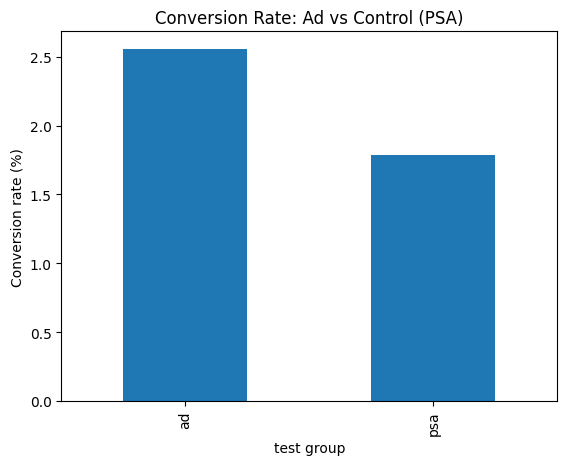

In [8]:
rates.plot(kind='bar')
plt.ylabel('Conversion rate (%)')
plt.title('Conversion Rate: Ad vs Control (PSA)')
plt.show()